# Netflix project

In [1]:
#importing the dependencies
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
#importing the CSV files
df = pd.read_csv(r"C:\Users\rahul\Downloads\mymoviedb.csv",engine="python")
#engine="python" tells pandas which method/Engine used to read CSV file

#Sometimes python shows an error with engine beacause it uses [ C ] engine as a default

In [4]:
df.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021-11-24,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021-12-22,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


In [5]:
#Give info of the dataframe (CSV)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9837 entries, 0 to 9836
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Release_Date       9837 non-null   str    
 1   Title              9828 non-null   str    
 2   Overview           9828 non-null   str    
 3   Popularity         9827 non-null   float64
 4   Vote_Count         9827 non-null   str    
 5   Vote_Average       9827 non-null   str    
 6   Original_Language  9827 non-null   str    
 7   Genre              9826 non-null   str    
 8   Poster_Url         9826 non-null   str    
dtypes: float64(1), str(8)
memory usage: 4.5 MB


In [6]:
df["Genre"].head()

0    Action, Adventure, Science Fiction
1              Crime, Mystery, Thriller
2                              Thriller
3    Animation, Comedy, Family, Fantasy
4      Action, Adventure, Thriller, War
Name: Genre, dtype: str

In [7]:
df.duplicated().sum() #i.e:No duplicate values

np.int64(0)

In [8]:
df[["Popularity","Vote_Count","Vote_Average"]].describe() #Here on popularaty is in numeric format so we get only it's description



,Popularity
count,9827.000000
mean,40.320570
std,108.874308
min,7.100000
25%,16.127500
50%,21.191000
75%,35.174500
max,5083.954000


• Exploration Summary  
• we have a dataframe consisting of 9827 rows and 9 columns.  
• our dataset looks a bit tidy with no NaNs nor duplicated values.  
• Release_Date column needs to be casted into date time and to extract only the year value.  
• Overview, Original_Language and Poster-Url wouldn’t be so useful during analysis, so we’ll drop them.  
• there is noticable outliers in Popularity column  
• Vote_Average betttere be categorised for proper analysis.  
• Genre column has comma seperated values and white spaces that needs to be handled and casted into category.


In [9]:
df.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021-11-24,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021-12-22,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


In [10]:
df['Release_Date'] = pd.to_datetime(df['Release_Date'],  errors='coerce')
print(df['Release_Date'].dtype)
#errors='coerce' = “Convert what you can, and for anything invalid, just mark it as missing (NaT) instead of breaking the code.


datetime64[us]


In [11]:
print("Hello")

Hello


In [12]:
df['Release_Date']=df['Release_Date'].dt.year
df['Release_Date'].dtypes


dtype('float64')

In [13]:
df.head()

,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021.0,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to...,5083.954,8940,8.3,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4i...
1,2022.0,The Batman,"In his second year of fighting crime, Batman u...",3827.658,1151,8.1,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R3...
2,2022.0,No Exit,Stranded at a rest stop in the mountains durin...,2618.087,122,6.3,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKl...
3,2021.0,Encanto,"The tale of an extraordinary family, the Madri...",2402.201,5076,7.7,en,"Animation, Comedy, Family, Fantasy",https://image.tmdb.org/t/p/original/4j0PNHkMr5...
4,2021.0,The King's Man,As a collection of history's worst tyrants and...,1895.511,1793,7.0,en,"Action, Adventure, Thriller, War",https://image.tmdb.org/t/p/original/aq4Pwv5Xeu...


#Dropping the unwanted columns

In [14]:
cols = ['Overview', 'Original_Language', 'Poster_Url']
df.drop(cols, axis=1, inplace=True,errors='ignore')  #errors='Ignore'ignores small errors such as 'Spellling mistakes'
print(df.columns)


Index(['Release_Date', 'Title', 'Popularity', 'Vote_Count', 'Vote_Average',
       'Genre'],
      dtype='str')


In [15]:
df.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre
0,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,"Action, Adventure, Science Fiction"
1,2022.0,The Batman,3827.658,1151,8.1,"Crime, Mystery, Thriller"
2,2022.0,No Exit,2618.087,122,6.3,Thriller
3,2021.0,Encanto,2402.201,5076,7.7,"Animation, Comedy, Family, Fantasy"
4,2021.0,The King's Man,1895.511,1793,7.0,"Action, Adventure, Thriller, War"


Categorizing Vote_Averege column
Vote_Averege=Popular,Averege,Below_Averege,Not_popular

In [17]:
print(df['Vote_Average'].dtype)
print(df['Vote_Average'].describe())

str
count     9827
unique      75
top        6.4
freq       435
Name: Vote_Average, dtype: object


In [18]:
df['Vote_Average'] = pd.to_numeric(df['Vote_Average'],errors='coerce')

'''pd.to_numeric(..., errors='coerce') = “Make everything numbers, and mark anything non‑numeric as missing.'''

"pd.to_numeric(..., errors='coerce') = “Make everything numbers, and mark anything non‑numeric as missing."

In [19]:
def categorize_column(df, col, labels):
    desc = df[col].describe()

    edges = [desc['min'],desc['50%'],desc['75%'],desc['max']]

    df[col + '_Category'] = pd.cut(df[col],edges,labels=labels,duplicates='drop')

    return df

In [20]:
labels = ['Not_popular', 'Below_avg','Popular']

categorize_column(df, 'Vote_Average', labels)
df['Vote_Average'].unique()

array([ 8.3,  8.1,  6.3,  7.7,  7. ,  6.6,  6.8,  5.3,  7.2,  5.9,  7.3,
        7.1,  5.1,  4.6,  6. ,  8.2,  5.4,  6.1,  8.4,  6.9,  5.8,  7.4,
        7.8,  8. ,  6.2,  6.7,  7.6,  8.6,  4.8,  5.5,  7.9,  6.4,  7.5,
        5.7,  2.2,  6.5,  0. ,  5.6,  5.2,  5. ,  8.5,  3.5,  4. ,  3.3,
        4.7,  4.2,  4.3,  2. ,  4.1,  4.9,  8.7,  4.5,  9.1,  4.4,  3.6,
        nan,  2.8,  3.9,  3.8,  9. ,  3. ,  3.1,  3.7,  3.4,  8.9,  2.9,
        8.8,  3.2,  1.5,  9.2,  2.5,  1.8,  2.4,  2.6, 10. ])

In [21]:
print(df.columns.tolist())

['Release_Date', 'Title', 'Popularity', 'Vote_Count', 'Vote_Average', 'Genre', 'Vote_Average_Category']


In [22]:
print('Vote_Average' in df.columns)

True


In [23]:
print(df.columns.tolist())
print('Vote_Average' in df.columns)
print(repr(df.columns))

['Release_Date', 'Title', 'Popularity', 'Vote_Count', 'Vote_Average', 'Genre', 'Vote_Average_Category']
True
Index(['Release_Date', 'Title', 'Popularity', 'Vote_Count', 'Vote_Average',
       'Genre', 'Vote_Average_Category'],
      dtype='str')


In [24]:
df.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Vote_Average_Category
0,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,"Action, Adventure, Science Fiction",Popular
1,2022.0,The Batman,3827.658,1151,8.1,"Crime, Mystery, Thriller",Popular
2,2022.0,No Exit,2618.087,122,6.3,Thriller,Not_popular
3,2021.0,Encanto,2402.201,5076,7.7,"Animation, Comedy, Family, Fantasy",Popular
4,2021.0,The King's Man,1895.511,1793,7.0,"Action, Adventure, Thriller, War",Below_avg


In [25]:
df['Vote_Average'].value_counts()

Vote_Average
6.4     435
6.3     429
6.5     427
6.8     423
6.7     420
       ... 
9.2       1
1.8       1
2.4       1
2.6       1
10.0      1
Name: count, Length: 74, dtype: int64

In [26]:
df.dropna(inplace=True)
df.isna().sum()

Release_Date             0
Title                    0
Popularity               0
Vote_Count               0
Vote_Average             0
Genre                    0
Vote_Average_Category    0
dtype: int64

We did split Genres into a list and then explode our Dataframe to have only genre per row for ezch movie

In [27]:
df['Genre']=df['Genre'].str.split(', ')
df=df.explode('Genre').reset_index(drop=True)
df.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Vote_Average_Category
0,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Action,Popular
1,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Adventure,Popular
2,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Science Fiction,Popular
3,2022.0,The Batman,3827.658,1151,8.1,Crime,Popular
4,2022.0,The Batman,3827.658,1151,8.1,Mystery,Popular


In [28]:
df['Genre']=df['Genre'].str.split(','' ')
df=df.explode('Genre').reset_index(drop=True)
df.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Vote_Average_Category
0,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Action,Popular
1,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Adventure,Popular
2,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Science Fiction,Popular
3,2022.0,The Batman,3827.658,1151,8.1,Crime,Popular
4,2022.0,The Batman,3827.658,1151,8.1,Mystery,Popular


In [29]:
#Casting column into category
df['Genre']=df['Genre'].astype('category')

df['Genre'].dtype

CategoricalDtype(categories=['Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
                  'Documentary', 'Drama', 'Family', 'Fantasy', 'History',
                  'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction',
                  'TV Movie', 'Thriller', 'War', 'Western'],
, ordered=False, categories_dtype=str)

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25551 entries, 0 to 25550
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   Release_Date           25551 non-null  float64 
 1   Title                  25551 non-null  str     
 2   Popularity             25551 non-null  float64 
 3   Vote_Count             25551 non-null  str     
 4   Vote_Average           25551 non-null  float64 
 5   Genre                  25551 non-null  category
 6   Vote_Average_Category  25551 non-null  category
dtypes: category(2), float64(3), str(2)
memory usage: 1.5 MB


* Data visualization

In [31]:
sns.set_style('whitegrid')

What is the most frequent genre of movies realesed on Netflix?
--> Drama Genre

In [32]:
df['Genre'].describe()

count     25551
unique       19
top       Drama
freq       3715
Name: Genre, dtype: object

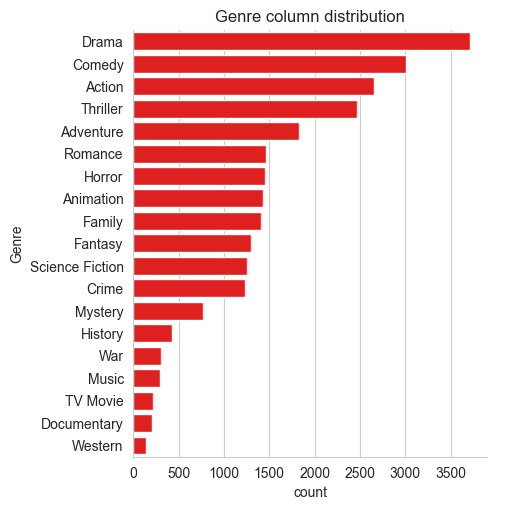

In [33]:
sns.catplot(y='Genre',data=df,kind='count',order=df['Genre'].value_counts().index,color='red')
plt.title("Genre column distribution")
plt.show()


Which has highest votes in vote avg column?
-->Drama

In [33]:
df.head()

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Vote_Average_Category
0,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Action,Popular
1,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Adventure,Popular
2,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Science Fiction,Popular
3,2022.0,The Batman,3827.658,1151,8.1,Crime,Popular
4,2022.0,The Batman,3827.658,1151,8.1,Mystery,Popular


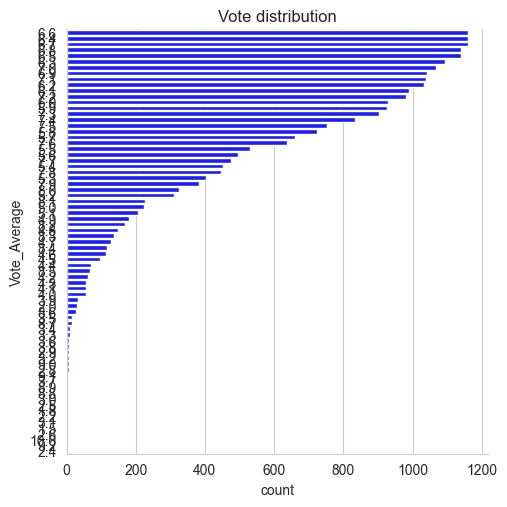

In [35]:
sns.catplot(y='Vote_Average',
            data=df,kind='count',order=df['Vote_Average'].value_counts().index,color='blue')
plt.title("Vote distribution")
plt.show()


What is the most frequent henre of movies realesed on Netflix?
-->Drama

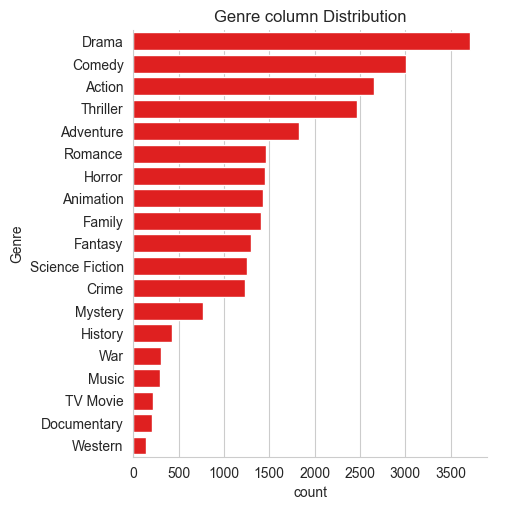

In [36]:
sns.catplot(y='Genre',data=df,kind='count',order=df['Genre'].value_counts().index,color='red')
plt.title('Genre column Distribution')
plt.show()

Which has highest vote in vote_avg column?

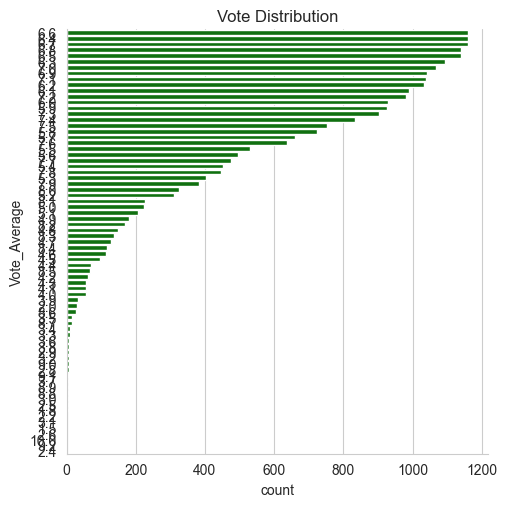

In [38]:
sns.catplot(y='Vote_Average',data=df,kind='count',order=df['Vote_Average'].value_counts().index,color='green')
plt.title('Vote Distribution')
plt.show()

WHich movie get highest popularity and what it's genre?

In [43]:
df[df['Popularity']==df['Popularity'].max()]

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Vote_Average_Category
0,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Action,Popular
1,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Adventure,Popular
2,2021.0,Spider-Man: No Way Home,5083.954,8940,8.3,Science Fiction,Popular


Movie with lowest popularity and what it's Genre?

In [44]:
df[df['Popularity']==df['Popularity'].min()]

,Release_Date,Title,Popularity,Vote_Count,Vote_Average,Genre,Vote_Average_Category
25545,2021.0,The United States vs. Billie Holiday,13.354,152,6.7,Music,Below_avg
25546,2021.0,The United States vs. Billie Holiday,13.354,152,6.7,Drama,Below_avg
25547,2021.0,The United States vs. Billie Holiday,13.354,152,6.7,History,Below_avg
25548,1984.0,Threads,13.354,186,7.8,War,Popular
25549,1984.0,Threads,13.354,186,7.8,Drama,Popular
25550,1984.0,Threads,13.354,186,7.8,Science Fiction,Popular


#Which year has most filmed year?
-->2020

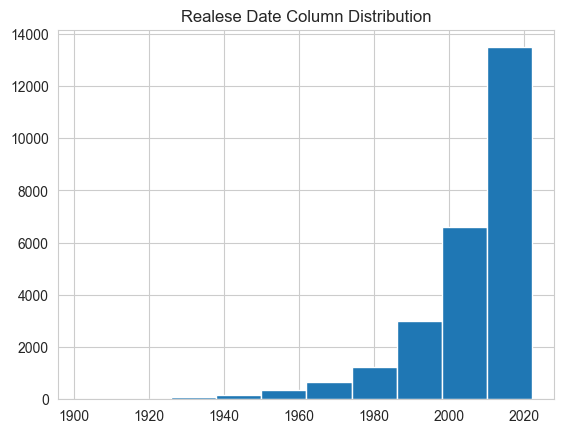

In [47]:
df['Release_Date'].hist()
plt.title('Realese Date Column Distribution')
plt.show()